In [1]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import tensorflow as tf

# Apple Silicon Macilla TensorFlow käyttää CPU:ta nopeempaa ja tarkempaa mallia varten
# tf.config.set_visible_devices([], "GPU")

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.layers import Input, Dense, Flatten
from keras.utils import to_categorical
from keras.models import Sequential
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [3]:
# Datasetin lataus
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species"
]

df = pd.read_csv(url, header=None, names=columns)

In [4]:
# tarkistetaan että datasetti latautui oikein
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [5]:
# Tarkistetaan tyhjät rivit datasetistä
df.isna().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [6]:
# Jaetaan kohde y:ksi ja piirteet x:ksi
x = df.drop(columns=["species"])
y = df["species"]

In [7]:
sepal_length_max = x["sepal_length"].max()
sepal_width_max = x["sepal_width"].max()
petal_length_max = x["petal_length"].max()
petal_width_max = x["petal_width"].max()

print(f"Verholehden maksimi pituus: {sepal_length_max}")
print(f"Verholehden maksimi leveys: {sepal_width_max}")
print(f"Terälehden maksimi pituus: {petal_length_max}")
print(f"Terälehden maksimi leveys: {petal_width_max}")

Verholehden maksimi pituus: 7.9
Verholehden maksimi leveys: 4.4
Terälehden maksimi pituus: 6.9
Terälehden maksimi leveys: 2.5


In [8]:
# Standardoidaan piirteet, että keskiarvo on 0 ja keskihajonta on 1
scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

# Muutetaan kohdearvot numeerisiksi
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# One-hot enkoodataan kohdearvot
y_onehot = to_categorical(y_encoded, 3)

# Tarkistetaan onnistuiko molemmat skaalaus ja onehot muokkaus lukemalla ekat 5
print("Onehot ekat 5:\n")
print(y_onehot[:5])
print("\n Skaalatut piirteet ekat 5:\n")
print(x_scaled[:5])

Onehot ekat 5:

[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]

 Skaalatut piirteet ekat 5:

[[-0.90068117  1.03205722 -1.3412724  -1.31297673]
 [-1.14301691 -0.1249576  -1.3412724  -1.31297673]
 [-1.38535265  0.33784833 -1.39813811 -1.31297673]
 [-1.50652052  0.10644536 -1.2844067  -1.31297673]
 [-1.02184904  1.26346019 -1.3412724  -1.31297673]]


In [9]:
# Tarkistetaan shape oikean inputin määrittämiseski
x_scaled.shape

(150, 4)

In [10]:
# Sekoitetaan dataa np.random.shufflella

# Luodaan satunnainen järjestys
indices = np.arange(len(x_scaled))
np.random.seed(42)
np.random.shuffle(indices)

# Sekoitetaan piirteet ja kohdearvot samassa järjestyksessä
x_shuffled = x_scaled[indices]
y_shuffled = y_onehot[indices]

In [11]:
# Alustetaan malli
model = Sequential([
    Input(shape=(4,)), # 4 shapea 4 eri piirrettä varten
    Flatten(), # tehdään yksiulotteiseksi arvot
    Dense(128, activation='relu'),
    Dense(3, activation='softmax') # 3 neuronia 3 luokkaa varten
    ])

2026-10-23 13:37:39.646811: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-10-23 13:37:39.646832: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-23 13:37:39.646838: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1792751859.646847 2003507 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792751859.646861 2003507 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [12]:
# Alustetaan optimoija
model.compile(optimizer='rmsprop',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [13]:
# luodaan stopperi datan oppimisen analysoinnin helpottamiseksi

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",     # monitoroi validation lossia
    patience=15,            # 15 peräkkäistä nousua
    restore_best_weights=True
)

In [14]:
import time

start = time.perf_counter()

history = model.fit(x_shuffled, y_shuffled, epochs=1000, validation_split=0.2, callbacks = [early_stop])

elapsed = time.perf_counter() - start
print(f"Koulutusaika: {elapsed:.2f} s")

Epoch 1/1000
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - accuracy: 0.8125 - loss: 0.9028

2026-10-23 13:37:39.944972: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.8167 - loss: 0.7869 - val_accuracy: 0.8333 - val_loss: 0.7239
Epoch 2/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8333 - loss: 0.6286 - val_accuracy: 0.8333 - val_loss: 0.6491
Epoch 3/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8333 - loss: 0.5583 - val_accuracy: 0.8333 - val_loss: 0.6008
Epoch 4/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8333 - loss: 0.5135 - val_accuracy: 0.8333 - val_loss: 0.5634
Epoch 5/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8417 - loss: 0.4784 - val_accuracy: 0.8333 - val_loss: 0.5333
Epoch 6/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8417 - loss: 0.4513 - val_accuracy: 0.8333 - val_loss: 0.5079
Epoch 7/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8417 - loss: 0.4294 - val_accuracy: 0.8333 - val_loss: 0.4875
Epoch 8/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8500 - loss: 0.4110 - val_accuracy: 0.8333 - val_loss: 0.46

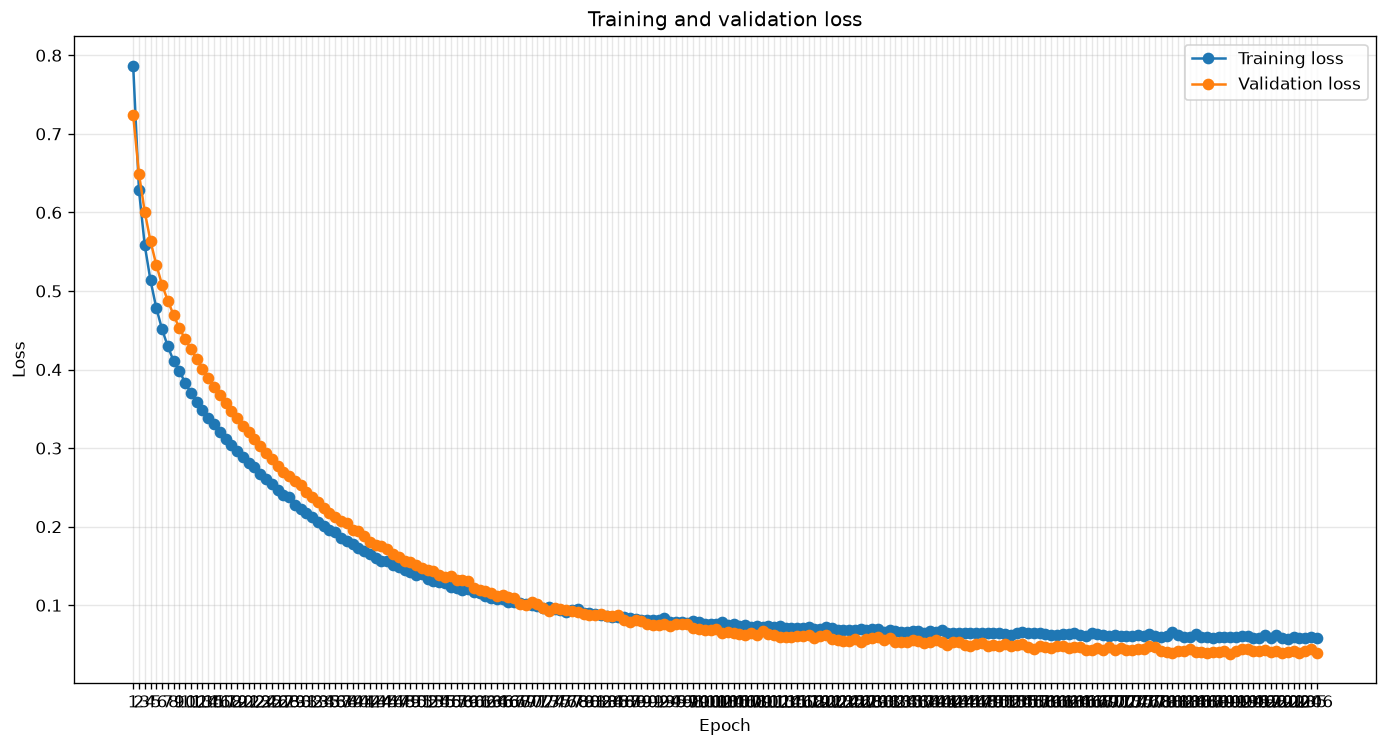

In [15]:
import matplotlib.pyplot as plt

epochs = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(14, 7), dpi=120)

plt.plot(epochs, history.history["loss"], marker="o", label="Training loss")
plt.plot(epochs, history.history["val_loss"], marker="o", label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and validation loss")

plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()